# Subgradients

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/06-ad/subgradients.ipynb)

Here is the function $f(x)=|x|$. Its slope is $-1$ to the left of zero and $+1$ to the right, so it has no derivative at $x=0$. Yet its minimum sits at that kink, and losses with kinks are common in scientific machine learning. The ReLU activation has a kink at zero. The $L^1$ penalty that makes lasso and SINDy coefficients sparse has a kink at every zero coefficient. What does automatic differentiation return at a kink, and what should an optimizer do with that number?

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

torch.set_default_dtype(torch.float64)
INK, BLUE, ORANGE, TEAL = '#253349', '#2f6fb5', '#db6a20', '#008577'
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})

def derivative_at(f, x0):
    x = torch.tensor(float(x0), requires_grad=True)
    f(x).backward()
    return x.grad.item()

## 1. What PyTorch returns at a kink

The next cell asks PyTorch for the derivative at $x=0$ of $|x|$ and of the ReLU, $\max(x,0)$, written three ways.

In [2]:
cases = {
    '`torch.abs(x)`': torch.abs,
    '`torch.relu(x)`': torch.relu,
    '`torch.clamp(x, min=0)`': lambda x: torch.clamp(x, min=0),
    '`torch.maximum(x, 0)`': lambda x: torch.maximum(x, torch.tensor(0.0)),
}
table = '| function | derivative PyTorch returns at 0 |\n|---|---|\n'
table += '\n'.join(f'| {name} | {derivative_at(f, 0.0):g} |' for name, f in cases.items())
display(Markdown(table))

| function | derivative PyTorch returns at 0 |
|---|---|
| `torch.abs(x)` | 0 |
| `torch.relu(x)` | 0 |
| `torch.clamp(x, min=0)` | 1 |
| `torch.maximum(x, 0)` | 0.5 |

PyTorch returns 0 for $|x|$. For the ReLU it returns 0, 1, or 0.5, depending on how we write the same function. Each library operation picks its own value at the kink. Which of these values are correct?

## 2. Lines below the graph

Away from a kink, the tangent line of a convex function lies below the graph and touches it at one point. At the kink of $|x|$ many lines through the origin stay below the graph, every line $y=gx$ with $-1\le g\le 1$. Each such slope is a **subgradient**. In general, $g$ is a subgradient of a convex function $f$ at $x$ when
$$f(z)\ge f(x)+g\,(z-x)\qquad\text{for every } z.$$
The set of all subgradients is the **subdifferential** $\partial f(x)$. For $|x|$ it is $\{-1\}$ for $x<0$, the interval $[-1,1]$ at $x=0$, and $\{1\}$ for $x>0$. Where $f$ is differentiable, $\partial f(x)$ contains only the derivative.

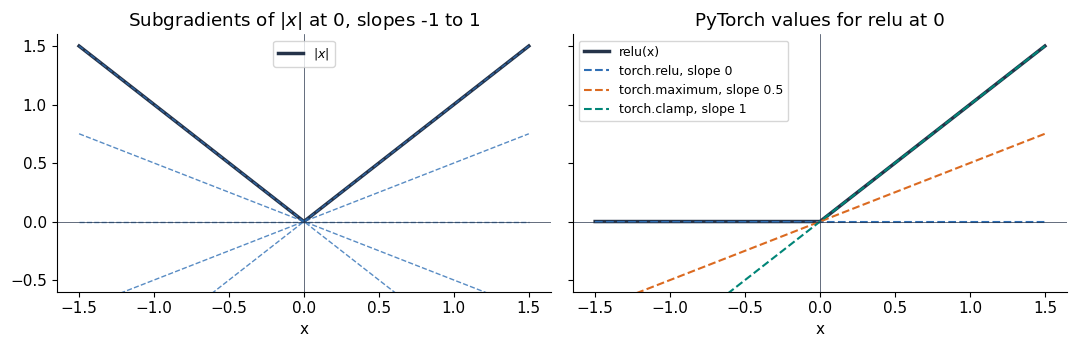

In [3]:
z = np.linspace(-1.5, 1.5, 301)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
axes[0].plot(z, np.abs(z), color=INK, lw=2.5, label='$|x|$')
for g in [-1, -0.5, 0, 0.5, 1]:
    axes[0].plot(z, g*z, '--', color=BLUE, lw=1, alpha=0.8)
axes[0].set(title='Subgradients of $|x|$ at 0, slopes -1 to 1', xlabel='x', ylim=(-0.6, 1.6))
axes[0].legend(fontsize=9, loc='upper center')
axes[1].plot(z, np.maximum(z, 0), color=INK, lw=2.5, label='relu(x)')
for g, label, color in [(0, 'torch.relu, slope 0', BLUE), (0.5, 'torch.maximum, slope 0.5', ORANGE),
                        (1, 'torch.clamp, slope 1', TEAL)]:
    axes[1].plot(z, g*z, '--', lw=1.5, color=color, label=label)
axes[1].set(title='PyTorch values for relu at 0', xlabel='x')
axes[1].legend(fontsize=9, loc='upper left')
for ax in axes:
    ax.axhline(0, color=INK, lw=0.5)
    ax.axvline(0, color=INK, lw=0.5)
fig.tight_layout()
plt.show()

The ReLU has the subdifferential $\partial\,\mathrm{relu}(0)=[0,1]$, and PyTorch's three values 0, 0.5, and 1 all lie in it. The value 0 for $|x|$ lies in $[-1,1]$. So each library choice is a subgradient of that one operation.

Subgradients also give the condition for a minimum. A point $x^\star$ minimizes a convex $f$ if and only if $0\in\partial f(x^\star)$, because the inequality with $g=0$ reads $f(z)\ge f(x^\star)$ for every $z$. For $|x|$ the interval $[-1,1]$ at $x=0$ contains 0, so the kink is the minimum. A smooth function needs $\nabla f=0$ at its minimum, and a function with kinks needs only $0\in\partial f$.

What happens when we use a subgradient in place of the gradient in gradient descent?

## 3. The subgradient method

The obvious move copies gradient descent, $x_{k+1}=x_k-\eta_k\,g_k$ with $g_k\in\partial f(x_k)$. Try it on $|x|$ from $x_0=1.05$ with a fixed step $\eta=0.1$. Every step before the kink moves the point 0.1 toward zero.

**Predict before running.** Where do the iterates go once they reach the kink?

fixed step, x_0 ... x_14: [ 1.05  0.95  0.85  0.75  0.65  0.55  0.45  0.35  0.25  0.15  0.05 -0.05
  0.05 -0.05  0.05]


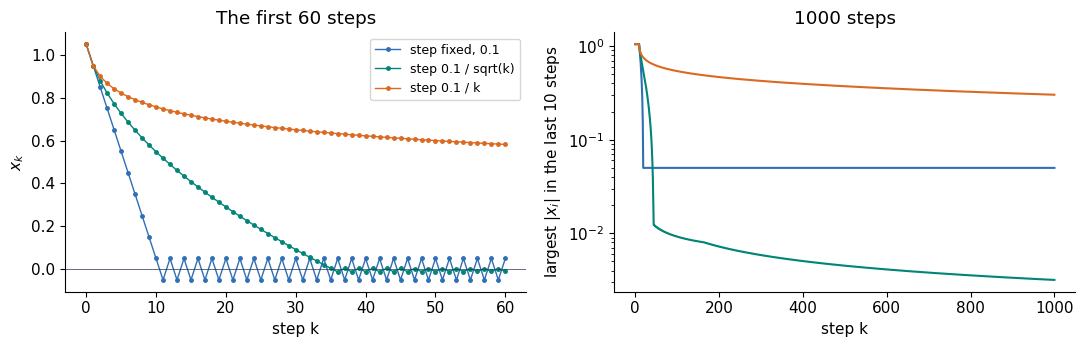

    fixed, 0.1: |x_1000| = 0.0500
 0.1 / sqrt(k): |x_1000| = 0.0032
       0.1 / k: |x_1000| = 0.3015


In [4]:
def subgradient_method(x0, step, n_steps):
    x, path = x0, [x0]
    for k in range(1, n_steps + 1):
        x = x - step(k)*np.sign(x)
        path.append(x)
    return np.array(path)

steps = {'fixed, 0.1': lambda k: 0.1, '0.1 / sqrt(k)': lambda k: 0.1/np.sqrt(k), '0.1 / k': lambda k: 0.1/k}
runs = {name: subgradient_method(1.05, step, 1000) for name, step in steps.items()}
print('fixed step, x_0 ... x_14:', np.round(runs['fixed, 0.1'][:15], 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for (name, path), color in zip(runs.items(), [BLUE, TEAL, ORANGE]):
    axes[0].plot(path[:61], 'o-', ms=2.5, lw=1, color=color, label=f'step {name}')
    # Largest |x_i| over the last 10 steps, which bounds the oscillation.
    window = np.array([np.abs(path[max(0, k - 9):k + 1]).max() for k in range(len(path))])
    axes[1].semilogy(window, color=color, lw=1.5, label=f'step {name}')
axes[0].axhline(0, color=INK, lw=0.5)
axes[0].set(xlabel='step k', ylabel='$x_k$', title='The first 60 steps')
axes[1].set(xlabel='step k', ylabel='largest $|x_i|$ in the last 10 steps', title='1000 steps')
axes[0].legend(fontsize=9)
fig.tight_layout()
plt.show()
for name, path in runs.items():
    print(f'{name:>14}: |x_1000| = {abs(path[-1]):.4f}')

The fixed step reaches 0.05 after 10 steps and then jumps between 0.05 and $-0.05$ forever. The subgradient of $|x|$ has size 1 at every point except zero, so the step never shrinks. A smooth loss behaves differently, because its gradient shrinks near the minimum and the step shrinks with it. The subgradient method therefore needs steps that shrink, and the steps must still add up to more than the distance to the minimum. With $\eta_k=0.1/\sqrt k$ the point is within 0.0032 of zero after 1000 steps, the size of the last step. With $\eta_k=0.1/k$ the steps add up to $0.1\,(1+\frac12+\dots+\frac1{1000})\approx0.75$, less than the starting distance 1.05, and the point stops at 0.30.

A standard bound makes this precise. Let $f$ be convex with subgradients of size at most $G$, and start at distance $R$ from a minimizer. The best value after $k$ steps satisfies
$$\min_{i\le k}f(x_i)-f^\star\le\frac{R^2+G^2\sum_{i\le k}\eta_i^2}{2\sum_{i\le k}\eta_i}.$$
A fixed step $\eta$ gives the limit $G^2\eta/2$ as $k\to\infty$, which is 0.05 for $|x|$ with $\eta=0.1$, the height at which the iterates bounce. Steps with $\eta_i\to0$ and $\sum\eta_i=\infty$ drive the bound to zero, and $\eta_i=c/\sqrt i$ makes it fall like $\log k/\sqrt k$.

The method is also not a descent method, so we keep the best point found so far. Take $f(\mathbf x)=|x_1|+2|x_2|$ at $(1,0)$. The vector $(1,2)$ is a subgradient there, and a step $-\eta\,(1,2)$ gives $f=(1-\eta)+4\eta=1+3\eta$, which is larger than $f(1,0)=1$.

Where does the kink matter for the answer itself, and not only for the step size?

## 4. Sparse regression

The lasso fits a linear model with an $L^1$ penalty,
$$F(\mathbf w)=\frac{1}{2n}\lVert X\mathbf w-\mathbf y\rVert^2+\lambda\lVert\mathbf w\rVert_1,$$
where $X$ is an $n\times p$ matrix with $n=50$ samples of $p=20$ features. The data come from a coefficient vector with four nonzero entries plus noise of size 0.1, and $\lambda=0.1$. The penalty pushes coefficients toward zero, and the minimizer has entries that are exactly zero.

The subgradient method treats the penalty like any other term, with $\lambda\operatorname{sign}(w_i)$ as its subgradient. The proximal gradient method, also called ISTA, separates the two terms. It takes a gradient step on the smooth part, $\mathbf z=\mathbf w-\eta\,\nabla\tfrac{1}{2n}\lVert X\mathbf w-\mathbf y\rVert^2$, and then solves one problem per coordinate,
$$\min_{w}\;t\,|w|+\tfrac12\,(w-z)^2,\qquad t=\eta\lambda.$$
The optimality condition $0\in t\,\partial|w|+(w-z)$ gives the soft threshold
$$S_t(z)=\operatorname{sign}(z)\max(|z|-t,\,0).$$
Every coordinate with $|z|\le t$ becomes zero, because $w=0$ satisfies the condition with the subgradient $z/t\in[-1,1]$.

**Predict before running.** How many coefficients does each method set to zero?

| method | objective F | exact zeros | coefficients below 1e-3 |
|---|---|---|---|
| subgradient, 20000 steps | 0.50880 | 0 | 15 |
| ISTA, 5000 steps | 0.50876 | 15 | 15 |
| scikit-learn Lasso | 0.50876 | 15 | 15 |


max |ISTA - scikit-learn|: 2.7e-13


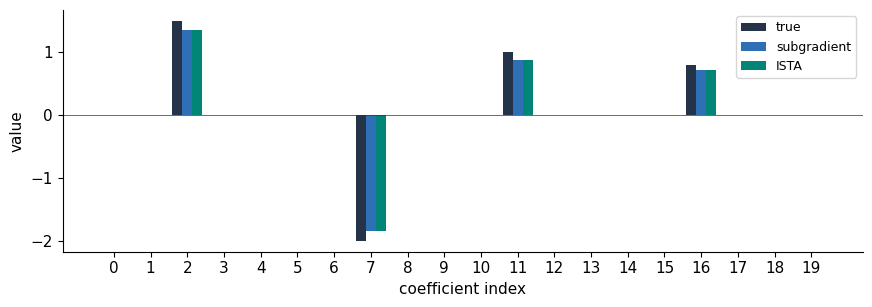

In [5]:
from sklearn.linear_model import Lasso

rng = np.random.default_rng(0)
n, p, lam = 50, 20, 0.1
X = rng.normal(size=(n, p))
w_true = np.zeros(p)
w_true[[2, 7, 11, 16]] = [1.5, -2.0, 1.0, 0.8]
y = X @ w_true + 0.1*rng.normal(size=n)

def objective(w):
    return 0.5/n*np.sum((X @ w - y)**2) + lam*np.sum(np.abs(w))

def smooth_gradient(w):
    return X.T @ (X @ w - y) / n

lipschitz = np.linalg.eigvalsh(X.T @ X / n).max()

# Subgradient method with steps (0.5 / lipschitz) / sqrt(k), keeping the best point.
w, best_value, w_sub = np.zeros(p), np.inf, np.zeros(p)
for k in range(1, 20_001):
    w = w - (0.5/lipschitz)/np.sqrt(k)*(smooth_gradient(w) + lam*np.sign(w))
    if objective(w) < best_value:
        best_value, w_sub = objective(w), w.copy()

# Proximal gradient (ISTA) with step 1 / lipschitz.
def soft_threshold(z, t):
    return np.sign(z)*np.maximum(np.abs(z) - t, 0)

w_ista, eta = np.zeros(p), 1/lipschitz
for _ in range(5000):
    w_ista = soft_threshold(w_ista - eta*smooth_gradient(w_ista), eta*lam)

reference = Lasso(alpha=lam, fit_intercept=False, tol=1e-12, max_iter=100_000).fit(X, y).coef_

table = '| method | objective F | exact zeros | coefficients below 1e-3 |\n|---|---|---|---|\n'
for name, w in [('subgradient, 20000 steps', w_sub), ('ISTA, 5000 steps', w_ista), ('scikit-learn Lasso', reference)]:
    table += f'| {name} | {objective(w):.5f} | {np.sum(w == 0)} | {np.sum(np.abs(w) < 1e-3)} |\n'
display(Markdown(table))
print(f'max |ISTA - scikit-learn|: {np.abs(w_ista - reference).max():.1e}')

fig, ax = plt.subplots(figsize=(9, 3.2))
idx = np.arange(p)
ax.bar(idx - 0.27, w_true, width=0.27, color=INK, label='true')
ax.bar(idx, w_sub, width=0.27, color=BLUE, label='subgradient')
ax.bar(idx + 0.27, w_ista, width=0.27, color=TEAL, label='ISTA')
ax.axhline(0, color=INK, lw=0.5)
ax.set(xlabel='coefficient index', ylabel='value', xticks=idx)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

The two methods reach nearly the same objective, 0.50880 for the subgradient method and 0.50876 for ISTA. ISTA's coefficients contain 15 exact zeros and match scikit-learn's lasso to $3\times10^{-13}$. The subgradient method returns no exact zeros. Fifteen of its coefficients are below $10^{-3}$, where each step jumps across zero, as the iterates on $|x|$ did. The lasso is sparse because of the kink, and only an update that solves the kink exactly returns the zeros. ISTA also keeps one small coefficient, 0.006, outside the four true ones.

## 5. Subgradients through the chain rule

AD applies the chain rule with one chosen value at each kink. For a single kink the result is a subgradient, as Section 2 showed. Compositions can break this. The function $f(x)=\mathrm{relu}(x)-\mathrm{relu}(-x)$ equals $x$ for every $x$, so $f'(0)=1$.

In [6]:
cases = {
    'relu(x) - relu(-x), which equals x': lambda x: torch.relu(x) - torch.relu(-x),
    'sqrt(x**2), which equals |x|': lambda x: torch.sqrt(x**2),
}
for name, f in cases.items():
    print(f'{name:>36}: at 0 -> {derivative_at(f, 0.0)}, at 0.001 -> {derivative_at(f, 1e-3)}')

  relu(x) - relu(-x), which equals x: at 0 -> 0.0, at 0.001 -> 1.0
        sqrt(x**2), which equals |x|: at 0 -> nan, at 0.001 -> 1.0


PyTorch returns 0, and 0 is not in $\partial f(0)=\{1\}$. The chain rule multiplies $\mathrm{relu}'(0)=0$ into both terms, and the two zeros add to zero. [Kakade and Lee](https://arxiv.org/abs/1809.08530) use a ReLU composition of this kind to show that AD libraries do not compute subgradients of compositions in general. The function $\sqrt{x^2}=|x|$ returns `nan` at 0, because its derivative is $x/\sqrt{x^2}$ and AD evaluates $0/0$. Away from the kink both functions get the correct derivative. [Bolte and Pauwels](https://arxiv.org/abs/2006.02080) show that for programs built from the usual nonsmooth pieces, the AD output differs from the derivative only on a set of measure zero. They also show that AD can create artificial critical points, which common stochastic training methods avoid with probability one.

The SINDy notebooks select the terms of a governing equation with sequentially thresholded least squares. That method sets small coefficients to zero and refits the rest. How does its threshold compare with the soft threshold $S_t$ of Section 4?

## Exercises

1. Find $\partial f(1)$ for $f(x)=\max(x,\;2x-1,\;-x)$. Then use the condition $0\in\partial f(x^\star)$ to find the minimizer.
2. Write $|x|$ as `torch.where(x >= 0, x, -x)` and find the derivative PyTorch returns at 0. Is it a subgradient?
3. Increase $\lambda$ until every lasso coefficient is zero. Predict that value from the condition $0\in\partial F(\mathbf 0)$, which gives $\lambda\ge\lVert X^T\mathbf y\rVert_\infty/n$, and check it.
4. Run the subgradient method on $f=|x_1|+2|x_2|$ from $(1,0.3)$ with a fixed step and with $\eta_k=0.1/\sqrt k$. Plot $f(\mathbf x_k)$ and the best value so far.

The [gradients and optimizers page](https://kks32-courses.github.io/sciml/06-ad/gradients-and-optimizers.html) shows what each optimizer does with a gradient. The [inverse-update notebook](https://kks32-courses.github.io/sciml/06-ad/inverse-updates.html) compares gradient descent, Newton, and inverse-simulator steps.